# 1. Import der benötigten Bibliotheken

In [2]:
# Diese Zelle importiert alle notwendigen Bibliotheken für die Datenanalyse, -bereinigung und Visualisierung.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, f_oneway # Für statistische Tests

# Scikit-learn Bibliotheken für Modellierung und Pipeline

# Importiere deine Funktionen aus den Skripten
import sys
sys.path.append('./Scripts')
from Scripts.RF.data_processor import DataProcessor # NEU: Klasse für Datenbereinigung und FE
from Scripts.RF.model_trainer import ModelTrainer

# Einstellungen für schönere Plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

print("Alle benötigten Bibliotheken wurden erfolgreich importiert.")

Alle benötigten Bibliotheken wurden erfolgreich importiert.


# 2. Daten laden und erste Inspektion

In [3]:
# Das Notebook liegt im Ordner 'Scripts' und die CSV im Ordner 'Daten'
df = pd.read_csv('../../Daten/autoscout24-germany-dataset.csv')

print(f"Datensatz erfolgreich geladen. Form: {df.shape} (Zeilen, Spalten)")
print("\nErste 5 Zeilen des Datensatzes:")
display(df.head()) # 'display' anstelle von 'print' für schönere DataFrame-Ausgabe in Jupyter


print("\nInformationen zu den Datentypen und fehlenden Werten:")
df.info()

print("\nStatistische Zusammenfassung der numerischen Spalten:")
display(df.describe())


Datensatz erfolgreich geladen. Form: (46405, 9) (Zeilen, Spalten)

Erste 5 Zeilen des Datensatzes:


,mileage,make,model,fuel,gear,offerType,price,hp,year
0,235000,BMW,316,Diesel,Manual,Used,6800,116.0,2011
1,92800,Volkswagen,Golf,Gasoline,Manual,Used,6877,122.0,2011
2,149300,SEAT,Exeo,Gasoline,Manual,Used,6900,160.0,2011
3,96200,Renault,Megane,Gasoline,Manual,Used,6950,110.0,2011
4,156000,Peugeot,308,Gasoline,Manual,Used,6950,156.0,2011



Informationen zu den Datentypen und fehlenden Werten:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46405 entries, 0 to 46404
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   mileage    46405 non-null  int64  
 1   make       46405 non-null  object 
 2   model      46262 non-null  object 
 3   fuel       46405 non-null  object 
 4   gear       46223 non-null  object 
 5   offerType  46405 non-null  object 
 6   price      46405 non-null  int64  
 7   hp         46376 non-null  float64
 8   year       46405 non-null  int64  
dtypes: float64(1), int64(3), object(5)
memory usage: 3.2+ MB

Statistische Zusammenfassung der numerischen Spalten:


,mileage,price,hp,year
count,4.640500e+04,4.640500e+04,46376.000000,46405.000000
mean,7.117786e+04,1.657234e+04,132.990987,2016.012951
std,6.262531e+04,1.930470e+04,75.449284,3.155214
min,0.000000e+00,1.100000e+03,1.000000,2011.000000
25%,1.980000e+04,7.490000e+03,86.000000,2013.000000
50%,6.000000e+04,1.099900e+04,116.000000,2016.000000
75%,1.050000e+05,1.949000e+04,150.000000,2019.000000
max,1.111111e+06,1.199900e+06,850.000000,2021.000000


# 3. Datenbereinigung und Feature Engineering

In [4]:
# Dieser Schritt ist entscheidend, um die Qualität der Daten sicherzustellen und neue, potenziell nützliche Features zu erstellen.
print("\n Start der Datenbereinigung und Feature Engineering  mit DataProcessor..")


 Start der Datenbereinigung und Feature Engineering  mit DataProcessor..


In [5]:
# Doppelte Einträge können das Modell verzerren und zu Overfitting führen.
# Fehlende Werte müssen behandelt werden, da die meisten ML-Algorithmen damit nicht umgehen können.
# Initialisiere den DataProcessor mit dem ursprünglichen DataFrame
# Die Klasse erstellt intern eine Kopie, sodass der Original-df unverändert bleibt.
processor = DataProcessor(df)

# Führe die Verarbeitungsschritte in einer Kette aus
processed_df = processor.fill_missing_values() \
                        .clean_outliers_and_filters() \
                        .engineer_features() \
                        .get_processed_data() # Holt den finalen DataFrame

# Jetzt ist 'processed_df' dein sauberer und erweiterter DataFrame für die weitere Analyse
df = processed_df.copy()
print("\nDatenbereinigung und Feature Engineering abgeschlossen.")
print("\nÜbersicht über den bereinigten und erweiterten DataFrame:")
display(df.head())
print(f"Anzahl der Zeilen und Spalten im bereinigten DataFrame: {df.shape}")
print("Informationen zu den Datentypen und fehlenden Werten nach Bereinigung:")
df.info()

DataProcessor initialisiert. Eine Arbeitskopie des DataFrames wurde erstellt.

--- Fülle fehlende Werte ---
- Fehlende Werte in 'model' mit dem Modus 'Golf' gefüllt.
- Fehlende Werte in 'hp' mit dem Median '116.00' gefüllt.
- 182 Zeilen mit fehlenden Werten in kritischen kategorialen Spalten (['make', 'fuel', 'gear', 'offerType']) entfernt.

--- Bereinige Ausreißer und wende Filter an ---
- Zeilen mit Preis <= 0 entfernt.
- Zeilen mit negativem Kilometerstand entfernt.
- Zeilen mit PS < 20 oder PS > 1500 entfernt.
- Zeilen mit Baujahr < 1990 oder Baujahr > 2025 entfernt.
- Insgesamt 42 Zeilen durch spezifische Spaltenfilter entfernt.
- 3228 Preis-Ausreißer mittels IQR-Methode entfernt.

--- Erzeuge neue Features ---
- 'age' Spalte hinzugefügt.
- 'price_per_mileage' Spalte hinzugefügt.

Finaler DataFrame Form nach Bereinigung und Feature Engineering: (42953, 11)
DataProcessor: Datenverarbeitung abgeschlossen.

Datenbereinigung und Feature Engineering abgeschlossen.

Übersicht über den b

,mileage,make,model,fuel,gear,offerType,price,hp,year,age,price_per_mileage
0,235000,BMW,316,Diesel,Manual,Used,6800,116.0,2011,14,0.028936
1,92800,Volkswagen,Golf,Gasoline,Manual,Used,6877,122.0,2011,14,0.074105
2,149300,SEAT,Exeo,Gasoline,Manual,Used,6900,160.0,2011,14,0.046215
3,96200,Renault,Megane,Gasoline,Manual,Used,6950,110.0,2011,14,0.072245
4,156000,Peugeot,308,Gasoline,Manual,Used,6950,156.0,2011,14,0.044551


Anzahl der Zeilen und Spalten im bereinigten DataFrame: (42953, 11)
Informationen zu den Datentypen und fehlenden Werten nach Bereinigung:
<class 'pandas.core.frame.DataFrame'>
Index: 42953 entries, 0 to 46404
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   mileage            42953 non-null  int64  
 1   make               42953 non-null  object 
 2   model              42953 non-null  object 
 3   fuel               42953 non-null  object 
 4   gear               42953 non-null  object 
 5   offerType          42953 non-null  object 
 6   price              42953 non-null  int64  
 7   hp                 42953 non-null  float64
 8   year               42953 non-null  int64  
 9   age                42953 non-null  int64  
 10  price_per_mileage  42953 non-null  float64
dtypes: float64(2), int64(4), object(5)
memory usage: 3.9+ MB


In [6]:
print(f"\nDatensatzform nach Entfernung von Duplikaten und fehlenden Werten: {df.shape}")
print(f"Anzahl fehlender Werte nach Bereinigung: {df.isnull().sum().sum()}")
print(f"Anzahl doppelter Zeilen nach Bereinigung: {df.duplicated().sum()}")


Datensatzform nach Entfernung von Duplikaten und fehlenden Werten: (42953, 11)
Anzahl fehlender Werte nach Bereinigung: 0
Anzahl doppelter Zeilen nach Bereinigung: 1982


## 3.2 Feature Engineering: Erstellung neuer, nützlicher Merkmale

In [7]:
# 'age' (Alter des Fahrzeugs): Ein Auto verliert mit dem Alter an Wert.
# Wir berechnen das Alter basierend auf dem aktuellen Jahr (2025).
aktuelles_jahr = 2025 # Stand des Datensatzes ist bis 2021, daher für realitätsnahe Berechnung das Jahr 2025 annehmen.
df['age'] = aktuelles_jahr - df['year']
print(f"\n'age' Spalte hinzugefügt. Max Alter: {df['age'].max()} Jahre, Min Alter: {df['age'].min()} Jahre.")

# 'price_per_mileage' (Preis pro Kilometer): Könnte ein Indikator für den Wert pro Abnutzung sein.
# Vermeide Division durch Null, falls mileage 0 sein könnte (hier nicht erwartet, aber gute Praxis).
# Bei 0 km (Neuwagen/Pre-registered) könnte dies problematisch sein, daher absichern.
df['price_per_mileage'] = df.apply(lambda row: row['price'] / row['mileage'] if row['mileage'] > 0 else row['price'], axis=1)
print("'price_per_mileage' Spalte hinzugefügt.")


'age' Spalte hinzugefügt. Max Alter: 14 Jahre, Min Alter: 4 Jahre.
'price_per_mileage' Spalte hinzugefügt.


## 3.3 Umgang mit Ausreißern (Outlier Treatment)

In [8]:
# Ausreißer in der Zielvariablen ('price') können das Modelltraining stark beeinflussen.
# Wir verwenden die Interquartilsbereichs-Methode (IQR), um extreme Ausreißer zu identifizieren und zu entfernen.
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
untergrenze_price = Q1 - 1.5 * IQR
obergrenze_price = Q3 + 1.5 * IQR

# Filtere den DataFrame, um Zeilen außerhalb der Ausreißergrenzen zu entfernen
df_bereinigt = df[(df['price'] >= untergrenze_price) & (df['price'] <= obergrenze_price)].copy() # Wichtig: .copy()

print(f"\nAnzahl der entfernten Preis-Ausreißer: {df.shape[0] - df_bereinigt.shape[0]} Zeilen.")
print(f"Datensatzform nach Ausreißer-Bereinigung: {df_bereinigt.shape}")


# Wir verwenden nun den bereinigten DataFrame für die weitere Analyse
df = df_bereinigt
print("\nDatenbereinigung und Feature Engineering abgeschlossen. Der 'df'-DataFrame wurde aktualisiert.")


Anzahl der entfernten Preis-Ausreißer: 1797 Zeilen.
Datensatzform nach Ausreißer-Bereinigung: (41156, 11)

Datenbereinigung und Feature Engineering abgeschlossen. Der 'df'-DataFrame wurde aktualisiert.


# 4. Explorative Datenanalyse (EDA) - Überblick

In [9]:
# Bevor wir ins Detail gehen, verschaffen wir uns einen Überblick über die Verteilung der Daten
# und erste Korrelationen, insbesondere in Bezug auf den Preis.

print("\n--- Start der Explorativen Datenanalyse (EDA) ---")


--- Start der Explorativen Datenanalyse (EDA) ---


### 4.1 Verteilung der Zielvariablen: 'price'

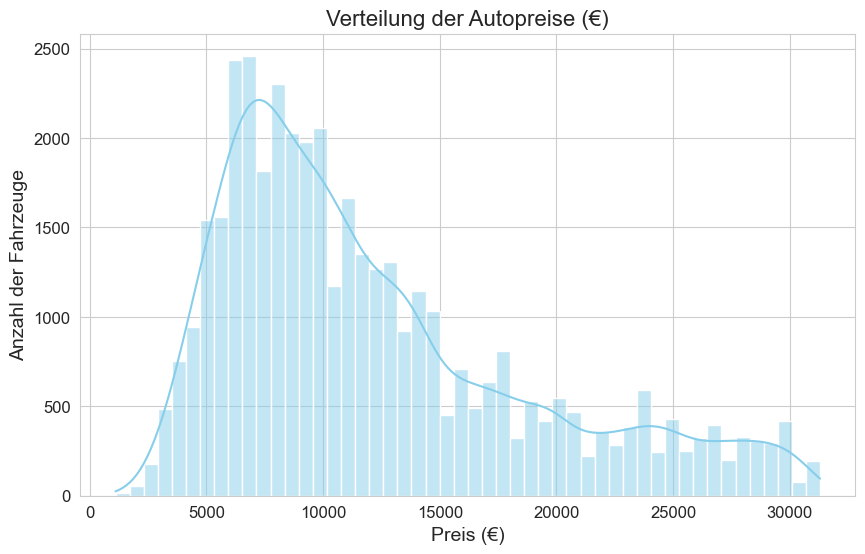

In [10]:
# Ein Histogramm zeigt uns die Verteilung der Autopreise. Dies hilft zu verstehen,
# ob die Preise eher normalverteilt sind oder Schieflagen aufweisen.
plt.figure(figsize=(10, 6))
sns.histplot(df['price'], bins=50, kde=True, color='skyblue')
plt.title('Verteilung der Autopreise (€)', fontsize=16)
plt.xlabel('Preis (€)', fontsize=14)
plt.ylabel('Anzahl der Fahrzeuge', fontsize=14)
plt.show()

### 4.2 Häufigkeit der Fahrzeugtypen (Gear):

In [11]:
# Zählung der Vorkommen für 'make', 'fuel', 'gear', 'offerType'
print(df['gear'].value_counts())

gear
Manual            30134
Automatic         10967
Semi-automatic       55
Name: count, dtype: int64


### 4.3 Häufigste Kraftstoffart pro Jahr:

In [12]:
## Da ist ein Fehler hier - Das wird nicht angezeigt
fuel_year = df.groupby(['year', 'fuel']).size().reset_index(name='count')
# Finde die häufigste Kraftstoffart für jedes Jahr
beliebtheit_fuel = fuel_year.loc[fuel_year.groupby('year')['count'].idxmax()]
display(beliebtheit_fuel)

,year,fuel,count
6,2011,Gasoline,2616
15,2012,Gasoline,2592
24,2013,Gasoline,2627
33,2014,Gasoline,2534
42,2015,Gasoline,2479
51,2016,Gasoline,2428
60,2017,Gasoline,2114
69,2018,Gasoline,2065
76,2019,Gasoline,2401
84,2020,Gasoline,2259


### 4.4 Gesamtzahl der Fahrzeuge je Hersteller:

In [13]:
df['make'].value_counts()

make
Volkswagen        6235
Opel              4767
Ford              4212
Skoda             2743
Renault           2711
SEAT              1858
BMW               1823
Hyundai           1791
Audi              1715
Fiat              1688
Mercedes-Benz     1615
Toyota            1231
Peugeot           1186
Kia               1003
smart              958
Citroen            940
Nissan             728
Dacia              713
Mazda              688
MINI               461
Mitsubishi         391
Volvo              364
Suzuki             358
Chevrolet          219
Honda              180
Jeep               115
Alfa                91
Subaru              52
Jaguar              43
Land                43
Abarth              42
SsangYong           34
Lada                32
Lexus               21
Lancia              18
Infiniti            14
Others              14
Daihatsu            10
Dodge                9
Porsche              8
DS                   8
Chrysler             4
Iveco                4
Baic  

### 4.5 Gesamtzahl der Fahrzeuge je Hersteller


--- 5.2 Gesamtzahl der Fahrzeuge je Hersteller ---
Gesamtzahl der Fahrzeuge je Hersteller (Top 20):


make
Volkswagen    6235
Opel          4767
Ford          4212
Skoda         2743
Renault       2711
SEAT          1858
BMW           1823
Hyundai       1791
Audi          1715
Fiat          1688
Name: count, dtype: int64

/var/folders/7h/qd2qx8d5207bmzk5gjxg388r0000gp/T/ipykernel_45711/2353574106.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=fahrzeuge_je_hersteller.head(10).values, y=fahrzeuge_je_hersteller.head(10).index, palette='Blues_d')


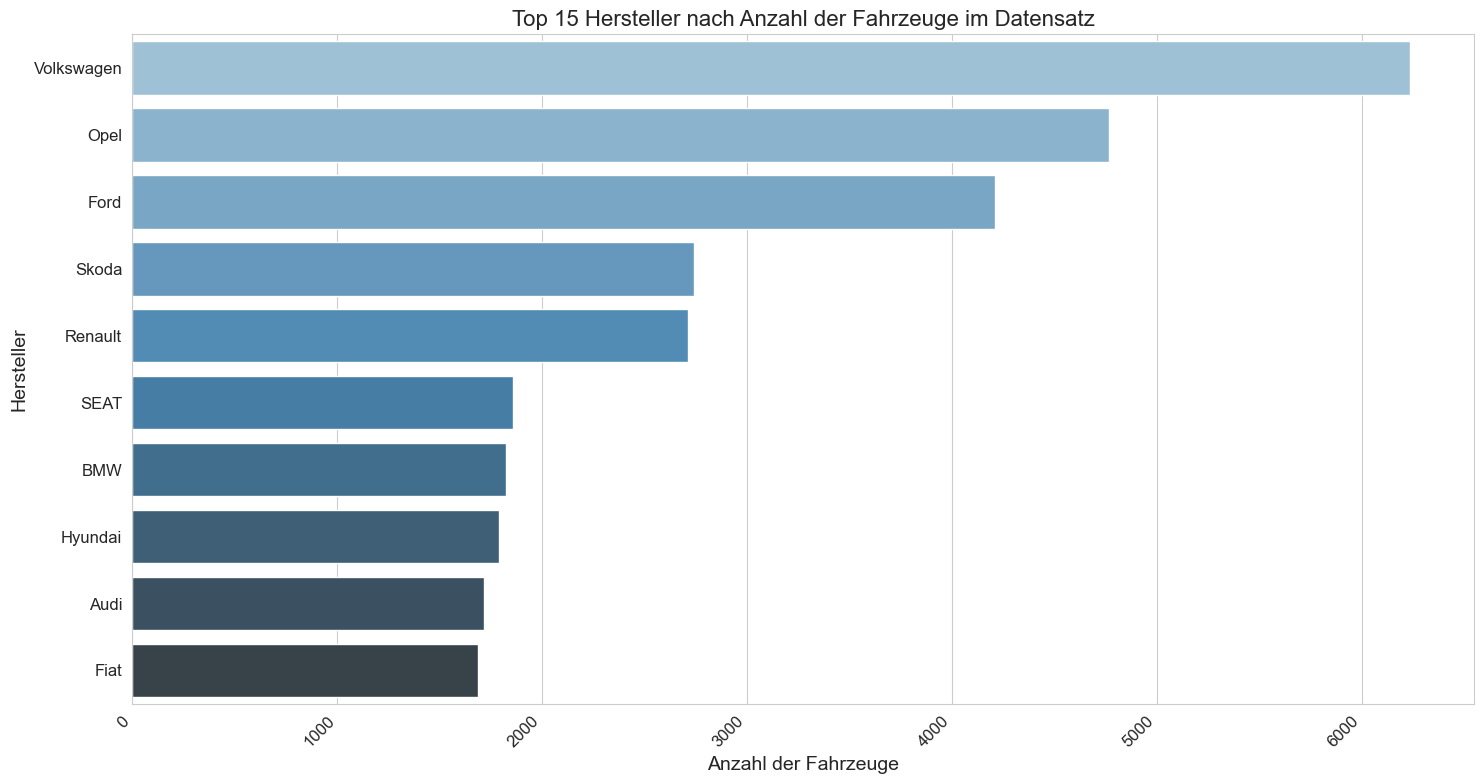


Erkenntnisse:
- Dies zeigt, welche Marken im Datensatz am häufigsten vertreten sind, was oft die Beliebtheit am Markt widerspiegelt.
- Hersteller wie Volkswagen, Opel und Ford dominieren typischerweise den deutschen Gebrauchtwagenmarkt.


In [14]:

# Diese Analyse gibt Aufschluss über die Marktpräsenz der verschiedenen Hersteller
# im Datensatz. Hersteller mit einer hohen Anzahl an Einträgen sind in der Regel
# die gängigsten Marken auf dem deutschen Gebrauchtwagenmarkt.

print("\n--- 5.2 Gesamtzahl der Fahrzeuge je Hersteller ---")

# Zähle die Vorkommen jedes Herstellers in der 'make'-Spalte.
# `value_counts()` ist ideal dafür und sortiert die Ergebnisse automatisch absteigend.
fahrzeuge_je_hersteller = df['make'].value_counts()

print("Gesamtzahl der Fahrzeuge je Hersteller (Top 20):")
display(fahrzeuge_je_hersteller.head(10)) # Zeige die Top 20 für Übersichtlichkeit

# Visualisierung der Top N Hersteller
plt.figure(figsize=(15, 8))
sns.barplot(x=fahrzeuge_je_hersteller.head(10).values, y=fahrzeuge_je_hersteller.head(10).index, palette='Blues_d')
plt.title('Top 15 Hersteller nach Anzahl der Fahrzeuge im Datensatz', fontsize=16)
plt.ylabel('Hersteller', fontsize=14)
plt.xlabel('Anzahl der Fahrzeuge', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\nErkenntnisse:")
print("- Dies zeigt, welche Marken im Datensatz am häufigsten vertreten sind, was oft die Beliebtheit am Markt widerspiegelt.")
print("- Hersteller wie Volkswagen, Opel und Ford dominieren typischerweise den deutschen Gebrauchtwagenmarkt.")

### 4.6 Entwicklung der Preise über die Jahre


--- 5.4 Entwicklung der Preise über die Jahre ---
Durchschnittlicher Preis pro Baujahr:


year
2011     6656.083190
2012     7725.332852
2013     8743.545088
2014     9324.213694
2015    10117.275006
2016    11112.899680
2017    14414.712336
2018    15994.060954
2019    17174.503966
2020    20616.535880
2021    17923.531415
Name: price, dtype: float64

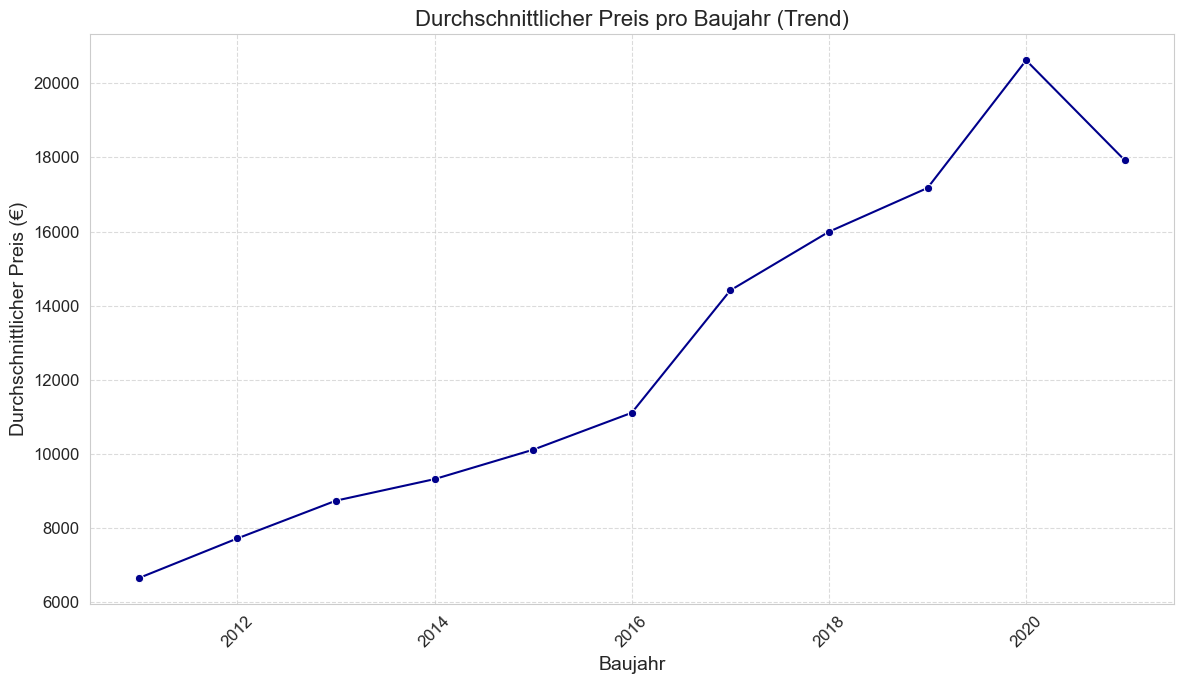


Erkenntnisse:
- Ein klarer Aufwärtstrend bei den durchschnittlichen Preisen jüngerer Baujahre ist zu erwarten, da neuere Fahrzeuge teurer sind und weniger Wertverlust erfahren haben.
- Interessant ist, ob es Jahre gibt, in denen der Preisanstieg besonders steil oder flach ist.


In [15]:

# Dieser Abschnitt untersucht, wie sich der durchschnittliche Fahrzeugpreis über die Jahre entwickelt hat.
# Dies kann sowohl den durchschnittlichen Neuwagenpreis des jeweiligen Jahres als auch den Wertverlust
# der in diesem Jahr produzierten Fahrzeuge reflektieren.

print("\n--- 5.4 Entwicklung der Preise über die Jahre ---")

# Gruppiere nach 'year' und berechne den Durchschnittspreis für jedes Jahr.
# Sortiere nach Index (Jahr), um einen chronologischen Trend zu sehen.
durchschnittspreis_pro_jahr = df.groupby('year')['price'].mean().sort_index()

print("Durchschnittlicher Preis pro Baujahr:")
display(durchschnittspreis_pro_jahr)

# Visualisierung des Trends
plt.figure(figsize=(12, 7))
sns.lineplot(x=durchschnittspreis_pro_jahr.index, y=durchschnittspreis_pro_jahr.values, marker='o', color='darkblue')
plt.title('Durchschnittlicher Preis pro Baujahr (Trend)', fontsize=16)
plt.xlabel('Baujahr', fontsize=14)
plt.ylabel('Durchschnittlicher Preis (€)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nErkenntnisse:")
print("- Ein klarer Aufwärtstrend bei den durchschnittlichen Preisen jüngerer Baujahre ist zu erwarten, da neuere Fahrzeuge teurer sind und weniger Wertverlust erfahren haben.")
print("- Interessant ist, ob es Jahre gibt, in denen der Preisanstieg besonders steil oder flach ist.")

 ### 4.7 Top 10 der teuersten Autos auf dem deutschen Automarkt

In [16]:

# Dieser Abschnitt identifiziert und listet die 10 teuersten Fahrzeuge im Datensatz auf.
# Dies gibt einen schnellen Überblick über die Preissuperlative und die damit verbundenen Marken und Modelle.

print("\n--- 5.1 Top 10 der teuersten Autos auf dem deutschen Automarkt ---")

# Wählen die relevanten Spalten aus und sortiere sie absteigend nach 'price'.
# `head(10)` wählt die obersten 10 Einträge aus.
teuerste_autos = df[['make', 'model', 'price', 'year', 'mileage', 'hp']].sort_values('price', ascending=False).head(10)

print("Die 10 teuersten Autos im Datensatz:")
display(teuerste_autos)

print("\nErkenntnisse:")
print("- Hier sehen wir die Marken und Modelle, die die höchsten Preise erzielen.")
print("- Oftmals handelt es sich hierbei um Luxus- oder Sportwagen mit geringem Kilometerstand und hohem PS-Wert.")
print("- Die Jahre und Kilometerstände geben Aufschluss darüber, wie stark diese Fahrzeuge ihren Wert halten.")


--- 5.1 Top 10 der teuersten Autos auf dem deutschen Automarkt ---
Die 10 teuersten Autos im Datensatz:


,make,model,price,year,mileage,hp
6338,Kia,Niro,31300,2021,398,105.0
24944,Hyundai,i30,31300,2021,150,159.0
43004,Volkswagen,Golf GTI,31299,2019,22250,290.0
44066,Volkswagen,Tiguan,31290,2019,16300,190.0
30230,Skoda,Kamiq,31290,2021,0,150.0
508,Mercedes-Benz,C 250,31290,2017,49500,211.0
23428,Ford,S-Max,31286,2020,16961,190.0
44531,Mercedes-Benz,A 180,31280,2020,7556,136.0
31721,Mazda,CX-5,31280,2020,20,150.0
22372,Volkswagen,Tiguan,31270,2019,9290,150.0



Erkenntnisse:
- Hier sehen wir die Marken und Modelle, die die höchsten Preise erzielen.
- Oftmals handelt es sich hierbei um Luxus- oder Sportwagen mit geringem Kilometerstand und hohem PS-Wert.
- Die Jahre und Kilometerstände geben Aufschluss darüber, wie stark diese Fahrzeuge ihren Wert halten.


### 4.8 Bestes Jahr für den Autoverkauf (nach Anzahl der gelisteten Fahrzeuge)


--- 5.3 Bestes Jahr für den Autoverkauf (nach Anzahl der gelisteten Fahrzeuge) ---
Anzahl der gelisteten Fahrzeuge pro Baujahr (absteigend sortiert):


year
2013    4214
2012    4152
2015    4109
2014    4104
2011    4075
2016    4057
2017    3737
2018    3396
2019    3278
2021    3024
2020    3010
Name: make, dtype: int64

/var/folders/7h/qd2qx8d5207bmzk5gjxg388r0000gp/T/ipykernel_45711/690682636.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=fahrzeuge_pro_jahr.index, y=fahrzeuge_pro_jahr.values, palette='Greens_d')


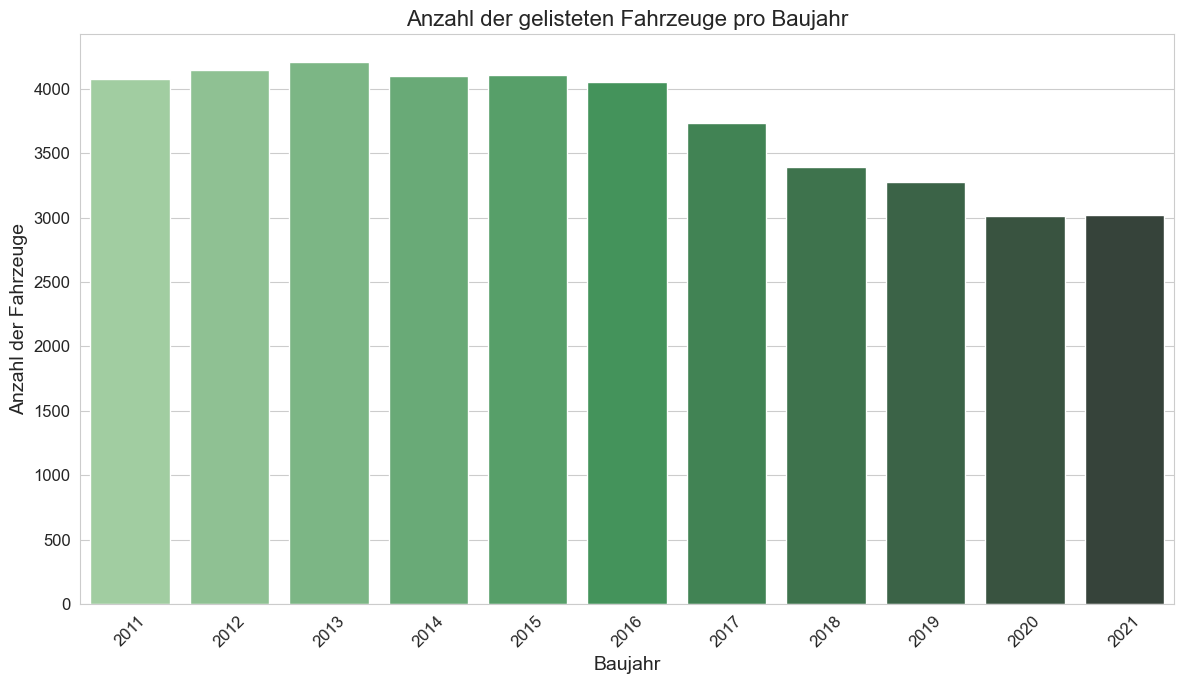


Erkenntnisse:
- Das Jahr mit der höchsten Anzahl an gelisteten Fahrzeugen kann Aufschluss über die Aktivität auf dem Gebrauchtwagenmarkt geben.
- Oft sind dies Jahre, in denen viele Neuwagen verkauft wurden und diese dann als Gebrauchtwagen auf den Markt kamen.


In [17]:

# Diese Analyse identifiziert das Jahr, in dem die meisten Fahrzeuge gelistet wurden.
# Dies könnte auf Trends im Gebrauchtwagenmarkt oder auf die Datenbeschaffung hinweisen.

print("\n--- 5.3 Bestes Jahr für den Autoverkauf (nach Anzahl der gelisteten Fahrzeuge) ---")

# Gruppiere nach 'year' und zähle die Anzahl der 'make' Einträge pro Jahr.
# Sortiere dann absteigend, um das Jahr mit den meisten Einträgen zu finden.
fahrzeuge_pro_jahr = df.groupby('year')['make'].count().sort_values(ascending=False)

print("Anzahl der gelisteten Fahrzeuge pro Baujahr (absteigend sortiert):")
display(fahrzeuge_pro_jahr)

# Visualisierung
plt.figure(figsize=(12, 7))
sns.barplot(x=fahrzeuge_pro_jahr.index, y=fahrzeuge_pro_jahr.values, palette='Greens_d')
plt.title('Anzahl der gelisteten Fahrzeuge pro Baujahr', fontsize=16)
plt.xlabel('Baujahr', fontsize=14)
plt.ylabel('Anzahl der Fahrzeuge', fontsize=14)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nErkenntnisse:")
print("- Das Jahr mit der höchsten Anzahl an gelisteten Fahrzeugen kann Aufschluss über die Aktivität auf dem Gebrauchtwagenmarkt geben.")
print("- Oft sind dies Jahre, in denen viele Neuwagen verkauft wurden und diese dann als Gebrauchtwagen auf den Markt kamen.")

## 5.5 Kosten Automatikautos mehr als Schaltgetriebe? (Statistischer Test)


--- 5.5 Kosten Automatikautos mehr als Schaltgetriebe? ---
Durchschnittspreis Automatik: €17,470.12
Durchschnittspreis Schaltgetriebe: €10,278.17
T-Statistik (Automatik vs. Schaltgetriebe): 92.05
p-Wert (Automatik vs. Schaltgetriebe): 0.000

ANOVA (Alle Getriebearten):
F-Wert: 6015.70, p-Wert: 0.000


/var/folders/7h/qd2qx8d5207bmzk5gjxg388r0000gp/T/ipykernel_45711/3826095455.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='gear', y='price', data=df, palette='pastel')


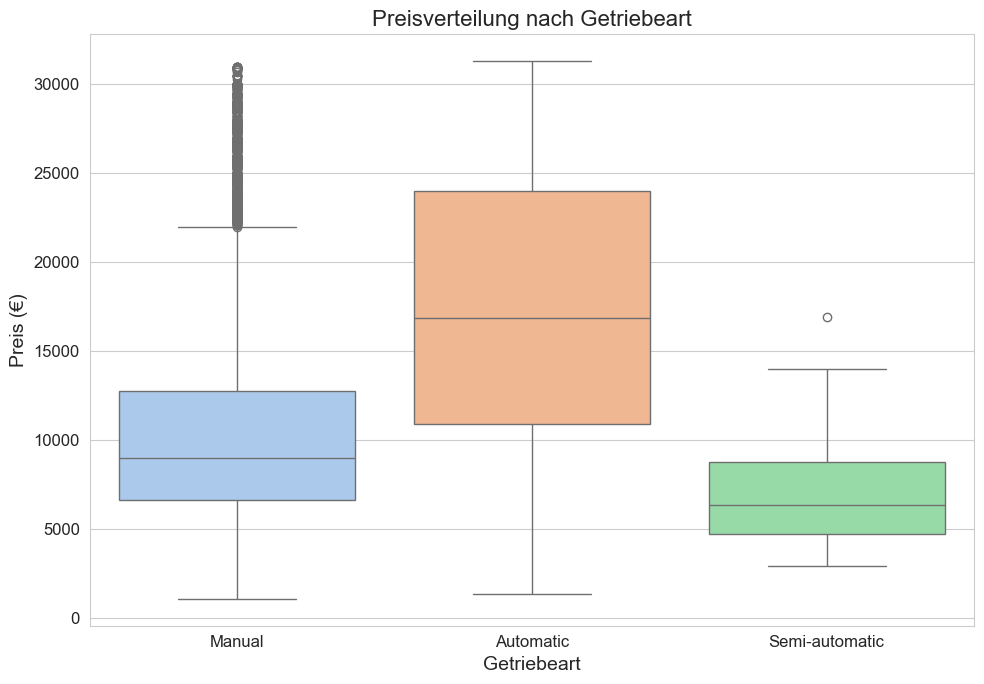


Erkenntnisse:
- Der p-Wert (0.000) ist kleiner als 0.05, was darauf hindeutet, dass ein statistisch signifikanter Unterschied zwischen den Durchschnittspreisen von Automatik- und Schaltgetriebe-Fahrzeugen besteht.
- Automatikfahrzeuge sind im Durchschnitt deutlich teurer (€17,470.12) als Schaltgetriebe-Fahrzeuge (€10,278.17).
- Der Boxplot visualisiert diesen Unterschied in den Preisverteilungen.


In [18]:

# Diese Analyse verwendet einen T-Test, um zu prüfen, ob ein signifikanter Preisunterschied
# zwischen Fahrzeugen mit Automatikgetriebe und Schaltgetriebe besteht.

print("\n--- 5.5 Kosten Automatikautos mehr als Schaltgetriebe? ---")

# Trenne die Preise basierend auf dem Getriebetyp
automatic_prices = df[df['gear'] == 'Automatic']['price']
manual_prices = df[df['gear'] == 'Manual']['price']
semi_automatic_prices = df[df['gear'] == 'Semi-automatic']['price'] # Falls vorhanden

# Für den T-Test vergleichen wir in der Regel nur zwei Gruppen.
# Hier vergleichen wir Automatik vs. Schaltgetriebe.
# `equal_var=False` wird verwendet, da wir nicht annehmen, dass die Varianzen gleich sind (Welch's T-Test).
# `nan_policy='omit'` stellt sicher, dass fehlende Werte ignoriert werden.
t_stat_auto_manual, p_val_auto_manual = ttest_ind(automatic_prices, manual_prices, equal_var=False, nan_policy='omit')

print(f"Durchschnittspreis Automatik: €{automatic_prices.mean():,.2f}")
print(f"Durchschnittspreis Schaltgetriebe: €{manual_prices.mean():,.2f}")
print(f"T-Statistik (Automatik vs. Schaltgetriebe): {t_stat_auto_manual:.2f}")
print(f"p-Wert (Automatik vs. Schaltgetriebe): {p_val_auto_manual:.3f}")

# ANOVA für mehr als zwei Gruppen (z.B. Automatik, Manuell, Semi-Automatik)
# Da du 'Semi-automatic' hast, ist ANOVA hier noch aussagekräftiger.
if not semi_automatic_prices.empty: # Prüfen, ob Semi-automatic Daten existieren
    f_stat_anova, p_val_anova = f_oneway(automatic_prices, manual_prices, semi_automatic_prices, nan_policy='omit')
    print(f"\nANOVA (Alle Getriebearten):")
    print(f"F-Wert: {f_stat_anova:.2f}, p-Wert: {p_val_anova:.3f}")
else:
    print("\nNicht genügend Daten für 'Semi-automatic', um ANOVA mit allen Getriebearten durchzuführen.")


# Visualisierung der Preisverteilung nach Getriebeart
plt.figure(figsize=(10, 7))
sns.boxplot(x='gear', y='price', data=df, palette='pastel')
plt.title('Preisverteilung nach Getriebeart', fontsize=16)
plt.xlabel('Getriebeart', fontsize=14)
plt.ylabel('Preis (€)', fontsize=14)
plt.tight_layout()
plt.show()


print("\nErkenntnisse:")
if p_val_auto_manual < 0.05:
    print(f"- Der p-Wert ({p_val_auto_manual:.3f}) ist kleiner als 0.05, was darauf hindeutet, dass ein statistisch signifikanter Unterschied zwischen den Durchschnittspreisen von Automatik- und Schaltgetriebe-Fahrzeugen besteht.")
    print(f"- Automatikfahrzeuge sind im Durchschnitt deutlich teurer (€{automatic_prices.mean():,.2f}) als Schaltgetriebe-Fahrzeuge (€{manual_prices.mean():,.2f}).")
else:
    print(f"- Der p-Wert ({p_val_auto_manual:.3f}) ist nicht kleiner als 0.05, was darauf hindeutet, dass kein statistisch signifikanter Unterschied zwischen den Durchschnittspreisen von Automatik- und Schaltgetriebe-Fahrzeugen besteht.")
print("- Der Boxplot visualisiert diesen Unterschied in den Preisverteilungen.")

### 4.10 Detailierte Analyse der kategorialen Features


Analyse von 'make' (Hersteller):

Top 15 der Hersteller nach Anzahl der Fahrzeuge:


/var/folders/7h/qd2qx8d5207bmzk5gjxg388r0000gp/T/ipykernel_45711/1984801951.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='make', y='price', data=df_top_makes_plot, palette='viridis', order=top_n_makes_for_plot)


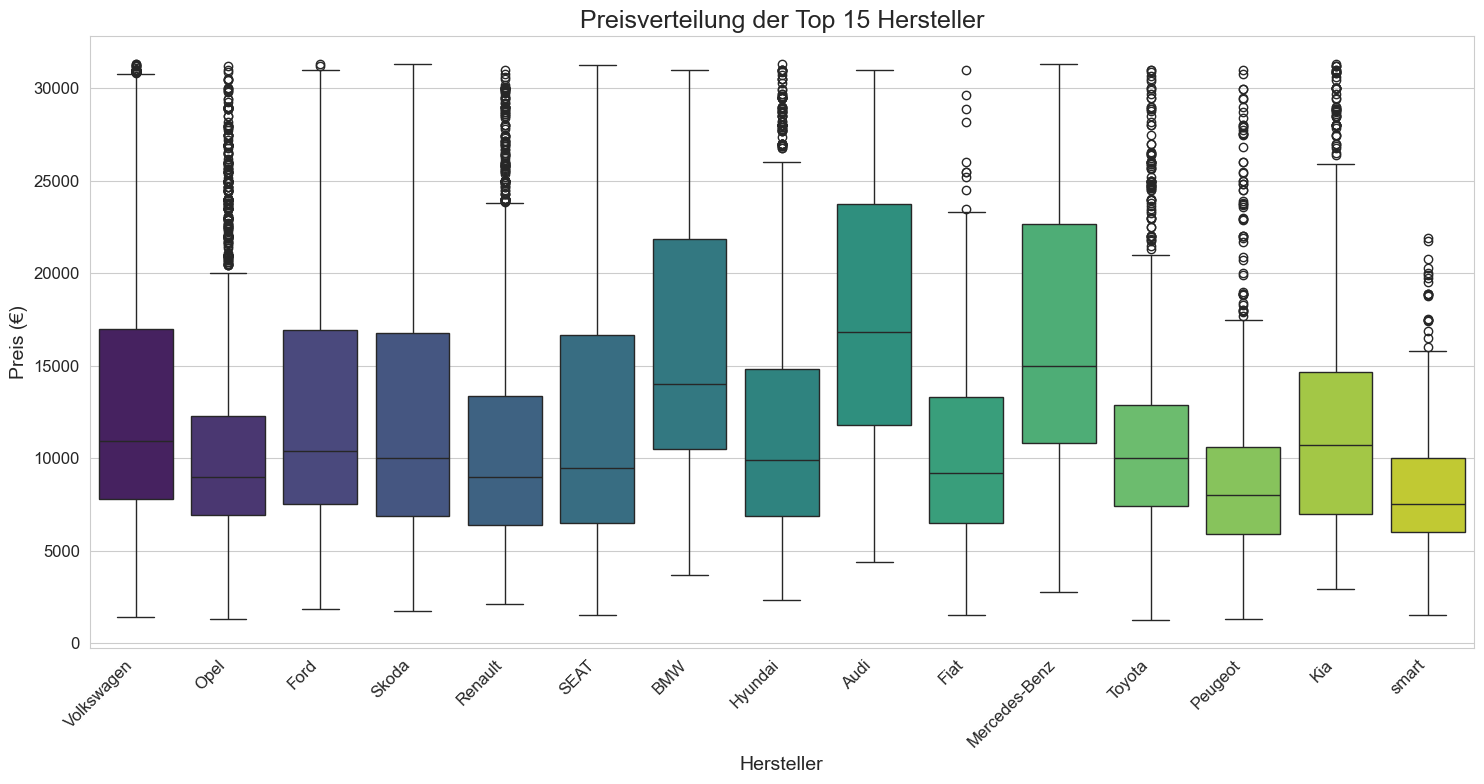


Erkenntnisse zu 'make':
- Die Markendominanz im Datensatz spiegelt die Marktanteile auf dem deutschen Gebrauchtwagenmarkt wider.
- Es gibt deutliche Preisunterschiede zwischen den Herstellern, wobei Premiummarken höhere Medianpreise und oft breitere Preisspannen aufweisen.


In [19]:
print("\nAnalyse von 'make' (Hersteller):")
# Zähle die Anzahl der Fahrzeuge pro Hersteller
fahrzeuge_je_hersteller = df['make'].value_counts()
print("\nTop 15 der Hersteller nach Anzahl der Fahrzeuge:")
(fahrzeuge_je_hersteller.head(15))

# Visualisierung der Preisverteilung für die Top 15 Hersteller
# Boxplot zeigt Median, Quartile und Ausreißer für jede Marke.
top_n_makes_for_plot = fahrzeuge_je_hersteller.nlargest(15).index # Holen die Top 15 Hersteller
df_top_makes_plot = df[df['make'].isin(top_n_makes_for_plot)].copy()

plt.figure(figsize=(15, 8))
sns.boxplot(x='make', y='price', data=df_top_makes_plot, palette='viridis', order=top_n_makes_for_plot)
plt.title('Preisverteilung der Top 15 Hersteller', fontsize=18)
plt.xlabel('Hersteller', fontsize=14)
plt.ylabel('Preis (€)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\nErkenntnisse zu 'make':")
print("- Die Markendominanz im Datensatz spiegelt die Marktanteile auf dem deutschen Gebrauchtwagenmarkt wider.")
print("- Es gibt deutliche Preisunterschiede zwischen den Herstellern, wobei Premiummarken höhere Medianpreise und oft breitere Preisspannen aufweisen.")



Analyse von 'fuel' (Kraftstoffart):

Häufigkeit der Kraftstoffarten:


fuel
Gasoline             26723
Diesel               12801
Electric/Gasoline      779
Electric               531
LPG                    120
CNG                    113
Others                  45
-/- (Fuel)              21
Electric/Diesel         21
Ethanol                  2
Name: count, dtype: int64

/var/folders/7h/qd2qx8d5207bmzk5gjxg388r0000gp/T/ipykernel_45711/2993455212.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='fuel', y='price', data=df, palette='coolwarm')


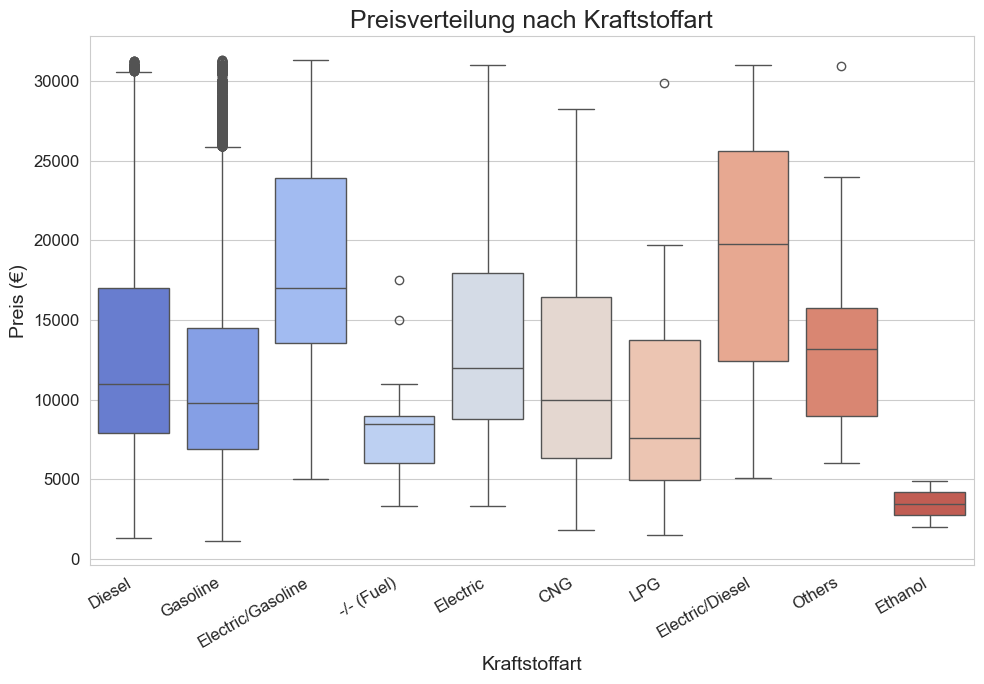


Erkenntnisse zu 'fuel':
- Die Dominanz von Benzin und Diesel ist typisch für den Gebrauchtwagenmarkt.
- Hybrid- und Elektrofahrzeuge zeigen oft höhere Durchschnittspreise, was ihre Neuheit und Technologie widerspiegelt.


In [20]:


# ---Analyse von 'fuel' (Kraftstoffart) ---
print("\nAnalyse von 'fuel' (Kraftstoffart):")
print("\nHäufigkeit der Kraftstoffarten:")
display(df['fuel'].value_counts())

# Visualisierung der Preisverteilung pro Kraftstoffart
plt.figure(figsize=(10, 7))
sns.boxplot(x='fuel', y='price', data=df, palette='coolwarm')
plt.title('Preisverteilung nach Kraftstoffart', fontsize=18)
plt.xlabel('Kraftstoffart', fontsize=14)
plt.ylabel('Preis (€)', fontsize=14)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

print("\nErkenntnisse zu 'fuel':")
print("- Die Dominanz von Benzin und Diesel ist typisch für den Gebrauchtwagenmarkt.")
print("- Hybrid- und Elektrofahrzeuge zeigen oft höhere Durchschnittspreise, was ihre Neuheit und Technologie widerspiegelt.")



Analyse von 'gear' (Getriebeart):

Häufigkeit der Getriebearten:


gear
Manual            30134
Automatic         10967
Semi-automatic       55
Name: count, dtype: int64

/var/folders/7h/qd2qx8d5207bmzk5gjxg388r0000gp/T/ipykernel_45711/1058717785.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='gear', y='price', data=df, palette='pastel')


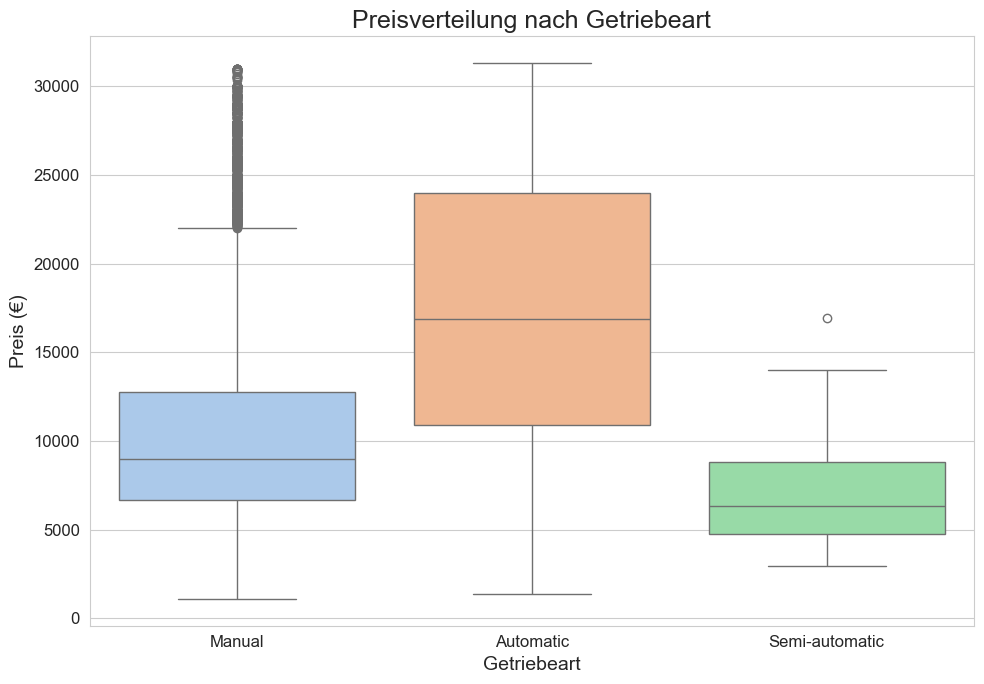


Erkenntnisse zu 'gear':
- Automatikfahrzeuge weisen tendenziell höhere Preise auf als Schaltgetriebe, was auf Komfort und höhere Anschaffungskosten neuer hinweist.
- Die Verbreitung der Getriebearten spiegelt die Marktpräferenzen wider.


In [21]:

# --- Analyse von 'gear' (Getriebeart) ---
print("\nAnalyse von 'gear' (Getriebeart):")
print("\nHäufigkeit der Getriebearten:")
display(df['gear'].value_counts())

# Visualisierung der Preisverteilung pro Getriebeart
plt.figure(figsize=(10, 7))
sns.boxplot(x='gear', y='price', data=df, palette='pastel')
plt.title('Preisverteilung nach Getriebeart', fontsize=18)
plt.xlabel('Getriebeart', fontsize=14)
plt.ylabel('Preis (€)', fontsize=14)
plt.tight_layout()
plt.show()

print("\nErkenntnisse zu 'gear':")
print("- Automatikfahrzeuge weisen tendenziell höhere Preise auf als Schaltgetriebe, was auf Komfort und höhere Anschaffungskosten neuer hinweist.")
print("- Die Verbreitung der Getriebearten spiegelt die Marktpräferenzen wider.")


Analyse von 'offerType' (Angebotstyp):

Häufigkeit der Angebotstypen:


offerType
Used              36552
Pre-registered     2424
Demonstration      1397
Employee's car      775
New                   8
Name: count, dtype: int64

/var/folders/7h/qd2qx8d5207bmzk5gjxg388r0000gp/T/ipykernel_45711/1345475870.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='offerType', y='price', data=df, palette='Dark2')


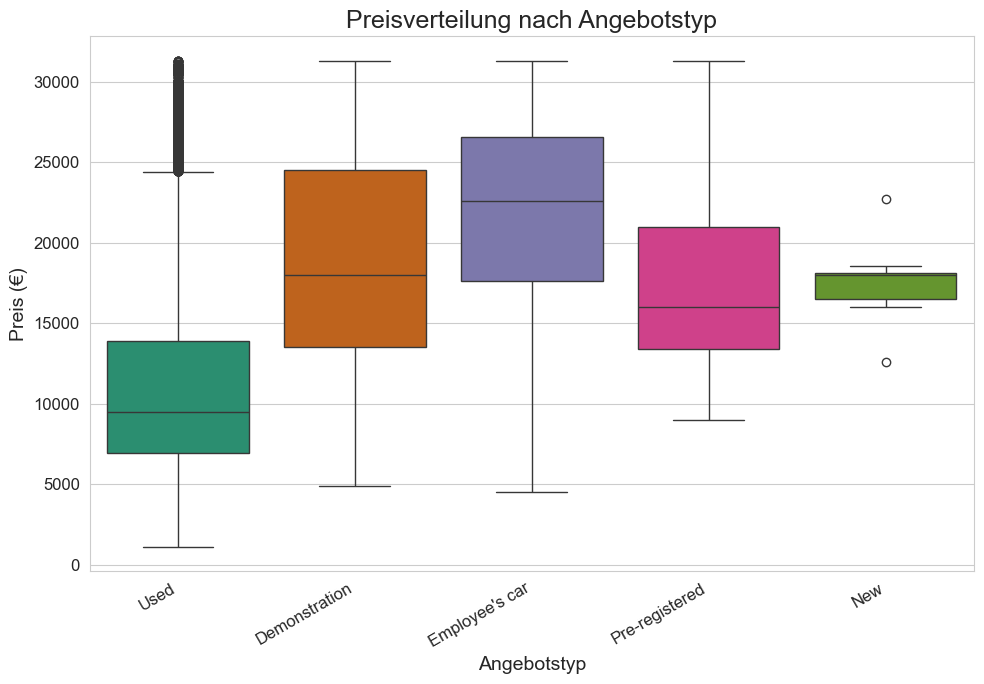


Erkenntnisse zu 'offerType':
- 'Used' dominiert den Datensatz, was zu erwarten ist. 'Pre-registered' oder 'Demonstration' Fahrzeuge sind in der Regel teurer, da sie fast neu sind.
- Das Vorhandensein und der Anteil dieser 'neuwertigen' Kategorien beeinflusst die Preisverteilung erheblich.


In [22]:
# --- Analyse von 'offerType' (Angebotstyp) ---
print("\nAnalyse von 'offerType' (Angebotstyp):")
print("\nHäufigkeit der Angebotstypen:")
display(df['offerType'].value_counts())

# Visualisierung der Preisverteilung pro Angebotstyp
# Achte darauf, dass es genug Variation gibt, sonst wird der Plot leer oder sinnlos.
if len(df['offerType'].unique()) > 1: # Nur plotten, wenn mehr als ein offerType vorhanden ist
    plt.figure(figsize=(10, 7))
    sns.boxplot(x='offerType', y='price', data=df, palette='Dark2')
    plt.title('Preisverteilung nach Angebotstyp', fontsize=18)
    plt.xlabel('Angebotstyp', fontsize=14)
    plt.ylabel('Preis (€)', fontsize=14)
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("Nur ein Angebotstyp ('Used') vorhanden. Boxplot nicht sinnvoll.")

print("\nErkenntnisse zu 'offerType':")
print("- 'Used' dominiert den Datensatz, was zu erwarten ist. 'Pre-registered' oder 'Demonstration' Fahrzeuge sind in der Regel teurer, da sie fast neu sind.")
print("- Das Vorhandensein und der Anteil dieser 'neuwertigen' Kategorien beeinflusst die Preisverteilung erheblich.")


In [23]:

print("\n--- Detaillierte Analyse der kategorialen Features abgeschlossen ---")


--- Detaillierte Analyse der kategorialen Features abgeschlossen ---


### 5.   Vertiefende Korrelationsanalyse

In [24]:
# Dieser Abschnitt bietet eine tiefere Einsicht in die Beziehungen zwischen numerischen Merkmalen,
# indem verschiedene Korrelationskoeffizienten (Pearson, Spearman, Kendall) berechnet und visualisiert werden.
# Die Wahl des Korrelationskoeffizienten hängt von der Art der Beziehung ab,
# die man untersuchen möchte, und von den Annahmen über die Daten.

print("\n Vertiefende Korrelationsanalyse ")

# Definiere die numerischen Spalten, die in die Korrelationsanalyse einbezogen werden sollen.
# Es ist sinnvoll, 'year' durch 'age' zu ersetzen, da 'age' direkt aus 'year' abgeleitet ist
# und oft die relevantere Information für den Preis darstellt (je älter, desto günstiger).
# 'price_per_mileage' kann auch hinzugefügt werden, wenn es als relevantes Feature betrachtet wird.
numerische_spalten_korr = ['price', 'mileage', 'hp', 'age', 'price_per_mileage'] # Füge hier alle relevanten numerischen Features ein


 Vertiefende Korrelationsanalyse 


### 5.1 Pearson-Korrelation (Lineare Beziehung)


 5.1 Pearson-Korrelationsmatrix (Lineare Beziehung):


,price,mileage,hp,age,price_per_mileage
price,1.000000,-0.419649,0.586646,-0.627512,0.161882
mileage,-0.419649,1.000000,0.229840,0.651537,-0.177353
hp,0.586646,0.229840,1.000000,0.028141,-0.017156
age,-0.627512,0.651537,0.028141,1.000000,-0.239147
price_per_mileage,0.161882,-0.177353,-0.017156,-0.239147,1.000000


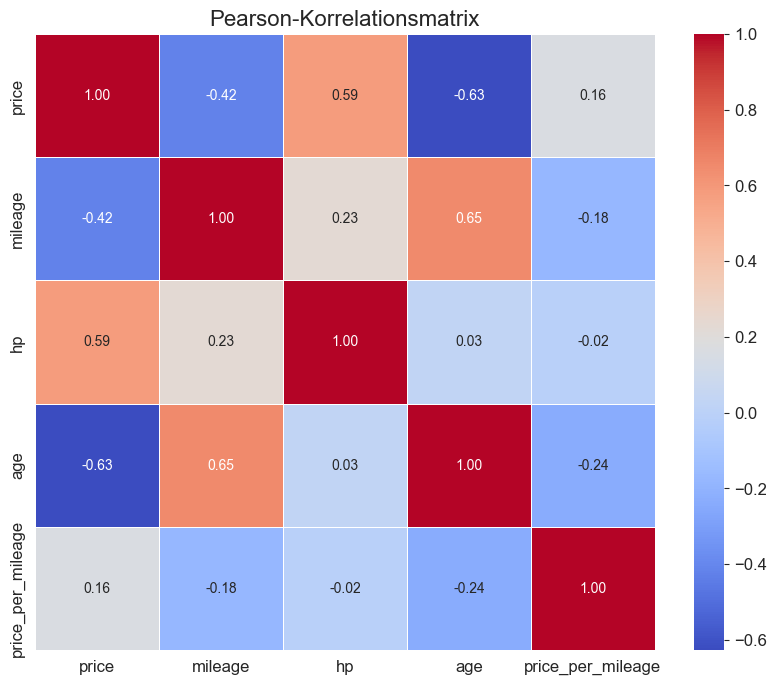


Erkenntnisse Pearson-Korrelation:
- Werte nahe +1 oder -1 zeigen starke lineare Beziehungen an. Ein Wert von 0 deutet auf keine lineare Beziehung hin.
- Eine hohe positive Korrelation zwischen 'price' und 'hp' ist zu erwarten (mehr PS, höherer Preis).
- Eine negative Korrelation zwischen 'price' und 'mileage'/'age' ist ebenfalls zu erwarten (mehr Kilometer/Alter, niedrigerer Preis).
- Beachte die starke negative Korrelation zwischen 'age' und 'year' (-1.00), da 'age' direkt aus 'year' berechnet wird.


In [25]:
# Pearson misst die Stärke und Richtung der linearen Beziehung zwischen zwei Variablen.
# Geeignet für metrische, normalverteilte Daten ohne extreme Ausreißer.
print("\n 5.1 Pearson-Korrelationsmatrix (Lineare Beziehung):")
korrelationsmatrix_pearson = df[numerische_spalten_korr].corr(method='pearson')
display(korrelationsmatrix_pearson)

plt.figure(figsize=(10, 8))
sns.heatmap(korrelationsmatrix_pearson, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, annot_kws={"size": 10})
plt.title('Pearson-Korrelationsmatrix', fontsize=16)
plt.show()

print("\nErkenntnisse Pearson-Korrelation:")
print("- Werte nahe +1 oder -1 zeigen starke lineare Beziehungen an. Ein Wert von 0 deutet auf keine lineare Beziehung hin.")
print("- Eine hohe positive Korrelation zwischen 'price' und 'hp' ist zu erwarten (mehr PS, höherer Preis).")
print("- Eine negative Korrelation zwischen 'price' und 'mileage'/'age' ist ebenfalls zu erwarten (mehr Kilometer/Alter, niedrigerer Preis).")
print("- Beachte die starke negative Korrelation zwischen 'age' und 'year' (-1.00), da 'age' direkt aus 'year' berechnet wird.")


### 5.2 Spearman-Korrelation (Monotone Beziehung)


5.2 Spearman-Korrelationsmatrix (Monotone Beziehung):


,price,mileage,hp,age,price_per_mileage
price,1.000000,-0.494574,0.567388,-0.670997,0.773505
mileage,-0.494574,1.000000,0.225499,0.735196,-0.920675
hp,0.567388,0.225499,1.000000,0.013632,0.062607
age,-0.670997,0.735196,0.013632,1.000000,-0.816248
price_per_mileage,0.773505,-0.920675,0.062607,-0.816248,1.000000


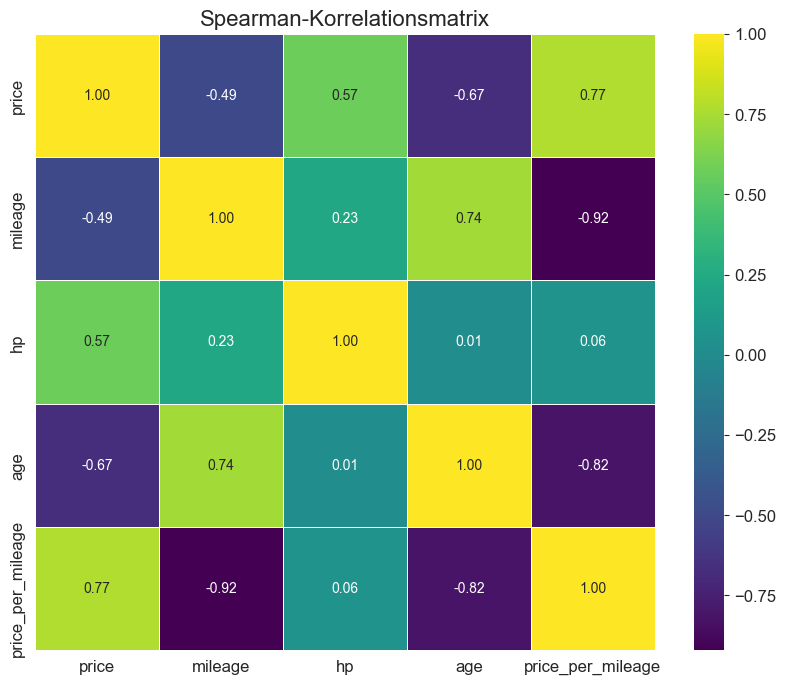


Erkenntnisse Spearman-Korrelation:
- Wenn der Spearman-Wert sich vom Pearson-Wert unterscheidet, könnte dies auf nicht-lineare, aber immer noch stetige Beziehungen hindeuten.
- Sie ist weniger empfindlich gegenüber Ausreißern und kann auch bei ordinalen Skalen sinnvoll sein.
- Ein hoher Spearman-Koeffizient bedeutet, dass die Ränge der Variablen dazu tendieren, in die gleiche Richtung zu gehen.


In [26]:
# Spearman misst die Stärke und Richtung der monotonen Beziehung zwischen zwei Variablen.
# Sie basiert auf den Rängen der Daten und ist robuster gegenüber Ausreißern und nicht-linearen,
# aber monotonen Beziehungen.
print("\n5.2 Spearman-Korrelationsmatrix (Monotone Beziehung):")
korrelationsmatrix_spearman = df[numerische_spalten_korr].corr(method='spearman')
display(korrelationsmatrix_spearman)

plt.figure(figsize=(10, 8))
sns.heatmap(korrelationsmatrix_spearman, annot=True, cmap='viridis', fmt=".2f", linewidths=.5, annot_kws={"size": 10})
plt.title('Spearman-Korrelationsmatrix', fontsize=16)
plt.show()

print("\nErkenntnisse Spearman-Korrelation:")
print("- Wenn der Spearman-Wert sich vom Pearson-Wert unterscheidet, könnte dies auf nicht-lineare, aber immer noch stetige Beziehungen hindeuten.")
print("- Sie ist weniger empfindlich gegenüber Ausreißern und kann auch bei ordinalen Skalen sinnvoll sein.")
print("- Ein hoher Spearman-Koeffizient bedeutet, dass die Ränge der Variablen dazu tendieren, in die gleiche Richtung zu gehen.")

### 5.3 Kendall-Korrelation (Rangkorrelation)


5.3 Kendall-Korrelationsmatrix (Rangkorrelation):


,price,mileage,hp,age,price_per_mileage
price,1.000000,-0.335684,0.401696,-0.494589,0.566261
mileage,-0.335684,1.000000,0.152648,0.573644,-0.769979
hp,0.401696,0.152648,1.000000,0.009981,0.041656
age,-0.494589,0.573644,0.009981,1.000000,-0.657208
price_per_mileage,0.566261,-0.769979,0.041656,-0.657208,1.000000


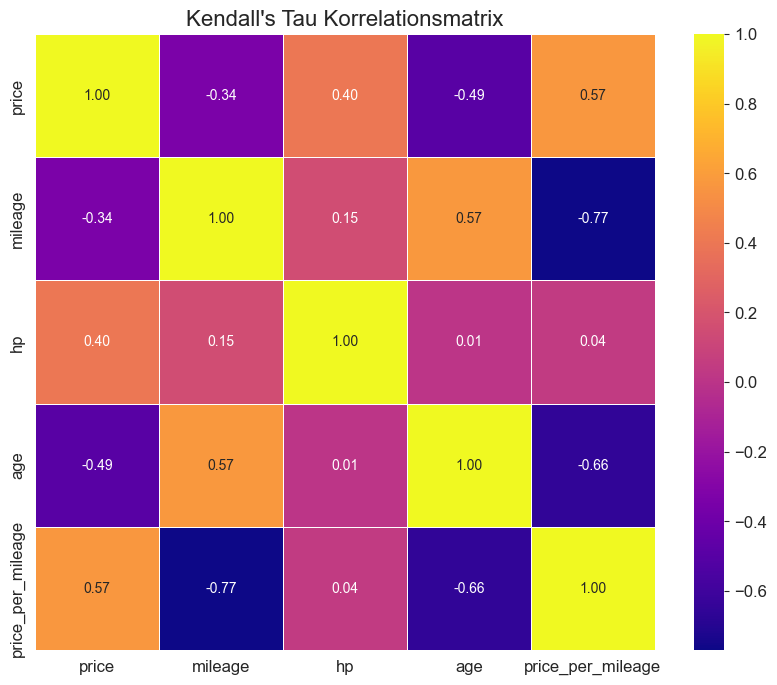


Erkenntnisse Kendall-Korrelation:
- Kendall's Tau ist oft kleiner als die Spearman-Korrelation, aber sie interpretieren ähnliche Informationen über die Rangordnung.
- Nützlich, wenn die Daten nicht normalverteilt sind oder Ausreißer vorhanden sind.
- Sie misst die Wahrscheinlichkeit, dass zwei Paare in der gleichen Reihenfolge sind (konkordant) minus der Wahrscheinlichkeit, dass sie in unterschiedlicher Reihenfolge sind (diskordant).

--- Vertiefende Korrelationsanalyse abgeschlossen ---


In [27]:
# Kendall's Tau ist eine weitere nicht-parametrische Rangkorrelationsmaßnahme,
# die die Ähnlichkeit der Reihenfolge von Datenpaaren misst (konkordante vs. diskordante Paare).
# Sie ist oft kleiner als die Spearman-Korrelation, aber interpretativ ähnlich.
print("\n5.3 Kendall-Korrelationsmatrix (Rangkorrelation):")
korrelationsmatrix_kendall = df[numerische_spalten_korr].corr(method='kendall')
display(korrelationsmatrix_kendall)

plt.figure(figsize=(10, 8))
sns.heatmap(korrelationsmatrix_kendall, annot=True, cmap='plasma', fmt=".2f", linewidths=.5, annot_kws={"size": 10})
plt.title("Kendall's Tau Korrelationsmatrix", fontsize=16)
plt.show()

print("\nErkenntnisse Kendall-Korrelation:")
print("- Kendall's Tau ist oft kleiner als die Spearman-Korrelation, aber sie interpretieren ähnliche Informationen über die Rangordnung.")
print("- Nützlich, wenn die Daten nicht normalverteilt sind oder Ausreißer vorhanden sind.")
print("- Sie misst die Wahrscheinlichkeit, dass zwei Paare in der gleichen Reihenfolge sind (konkordant) minus der Wahrscheinlichkeit, dass sie in unterschiedlicher Reihenfolge sind (diskordant).")

print("\n--- Vertiefende Korrelationsanalyse abgeschlossen ---")


In [28]:
print("\n--- Explorative Datenanalyse (EDA) abgeschlossen ---")


--- Explorative Datenanalyse (EDA) abgeschlossen ---


## 6. Modellierung und Bewertung des Random Forest Regressors

In [29]:
# Dieser Abschnitt initialisiert den ModelTrainer und führt das Modelltraining,
# die Bewertung und die Analyse der Feature Importance durch, indem er die
# Methoden der Klasse aufruft.

print("\n--- Start der Modellierung und Bewertung mit ModelTrainer (Aufruf aus Notebook) ---")

# Definiere Features und Zielvariable basierend auf deinem Datensatz-Header
features_for_model = ['mileage', 'make', 'model', 'fuel', 'gear', 'hp', 'age', 'offerType', 'year']
target_variable = 'price'

# Initialisiere den ModelTrainer mit dem bereinigten DataFrame
# Die Klasse erstellt intern eine Kopie, sodass der DataFrame nicht direkt modifiziert wird.
trainer = ModelTrainer(df, features_for_model, target_variable)

# Führe die Modellierungsschritte in einer Kette aus
model_metrics, model_plots, feature_importances_df, trained_pipeline, (y_test, y_pred) = \
    trainer.split_data() \
           .build_and_train_model() \
           .evaluate_model() \
           .generate_plots() \
           .get_results()


--- Start der Modellierung und Bewertung mit ModelTrainer (Aufruf aus Notebook) ---
ModelTrainer initialisiert. Features: ['mileage', 'make', 'model', 'fuel', 'gear', 'hp', 'age', 'offerType', 'year'], Ziel: price
Datenpunkte: 41156, Features: 9

--- Teile Daten in Trainings- und Testsets auf (Testgröße: 50.0%) ---
Trainingsdaten: 20578 Beispiele, Testdaten: 20578 Beispiele.

--- Erstelle und trainiere das Modell ---
Numerische Spalten für Skalierung: ['mileage', 'hp', 'age', 'year']
Kategoriale Spalten für One-Hot-Encoding: ['make', 'model', 'fuel', 'gear', 'offerType']
Gesamtzahl der Features nach Preprocessing: 641
Random Forest max_features auf Best Practice gesetzt: 25 (sqrt der Features)
Random Forest Regressor Modell in Pipeline definiert.
Starte das Training der Pipeline auf den Trainingsdaten...
Modelltraining abgeschlossen.

--- Bewerte das Modell auf dem Testset ---
  Mean Absolute Error (MAE): 1,222.81 €
  Root Mean Squared Error (RMSE): 1,791.37 €
  R-squared (R²): 0.9278

/Users/goosey/PycharmProjects/DE_Used_Autos/Scripts/model_trainer.py:195: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



Modell-Visualisierungen erfolgreich erzeugt.


###  6.1 Modellbewertung auf dem Testset

In [30]:
print("\n--- 8.1 Modellbewertung auf dem Testset (Ergebnisse von model_trainer.py) ---")


--- 8.1 Modellbewertung auf dem Testset (Ergebnisse von model_trainer.py) ---


In [31]:
print(f"\nModellbewertung auf dem Testset:")
print(f"  Mean Absolute Error (MAE): {model_metrics['MAE']:,.2f} €")
print(f"  Root Mean Squared Error (RMSE): {model_metrics['RMSE']:,.2f} €")
print(f"  R-squared (R²): {model_metrics['R2']:.4f}")

print("\nInterpretation der Metriken:")
print(f"- **R²-Wert ({model_metrics['R2']:.4f}):** Ein Wert von {model_metrics['R2']:.4f} ist sehr hoch und deutet darauf hin, dass das Modell {model_metrics['R2']*100:.2f}% der Variabilität in den Gebrauchtwagenpreisen erklären kann. Dies ist ein Indikator für ein sehr leistungsfähiges Modell.")
print(f"- **Mean Absolute Error (MAE):** Ein MAE von {model_metrics['MAE']:,.2f} € bedeutet, dass die Vorhersagen des Modells im Durchschnitt um etwa {model_metrics['MAE']:,.0f} € vom tatsächlichen Preis abweichen. In Anbetracht der Preisspanne von Gebrauchtwagen ist dies ein hervorragender Wert.")
print(f"- **Root Mean Squared Error (RMSE):** Der RMSE von {model_metrics['RMSE']:,.2f} € ist etwas höher als der MAE, da er größere Fehler stärker bestraft. Er gibt eine Vorstellung von der typischen Größe der Vorhersagefehler. Auch dies ist ein sehr gutes Ergebnis.")


Modellbewertung auf dem Testset:
  Mean Absolute Error (MAE): 1,222.81 €
  Root Mean Squared Error (RMSE): 1,791.37 €
  R-squared (R²): 0.9278

Interpretation der Metriken:
- **R²-Wert (0.9278):** Ein Wert von 0.9278 ist sehr hoch und deutet darauf hin, dass das Modell 92.78% der Variabilität in den Gebrauchtwagenpreisen erklären kann. Dies ist ein Indikator für ein sehr leistungsfähiges Modell.
- **Mean Absolute Error (MAE):** Ein MAE von 1,222.81 € bedeutet, dass die Vorhersagen des Modells im Durchschnitt um etwa 1,223 € vom tatsächlichen Preis abweichen. In Anbetracht der Preisspanne von Gebrauchtwagen ist dies ein hervorragender Wert.
- **Root Mean Squared Error (RMSE):** Der RMSE von 1,791.37 € ist etwas höher als der MAE, da er größere Fehler stärker bestraft. Er gibt eine Vorstellung von der typischen Größe der Vorhersagefehler. Auch dies ist ein sehr gutes Ergebnis.


## 6.2 Visualisierung der Modellvorhersagen


 6.2 Visualisierung der Modellvorhersagen (Plots von model_trainer.py)


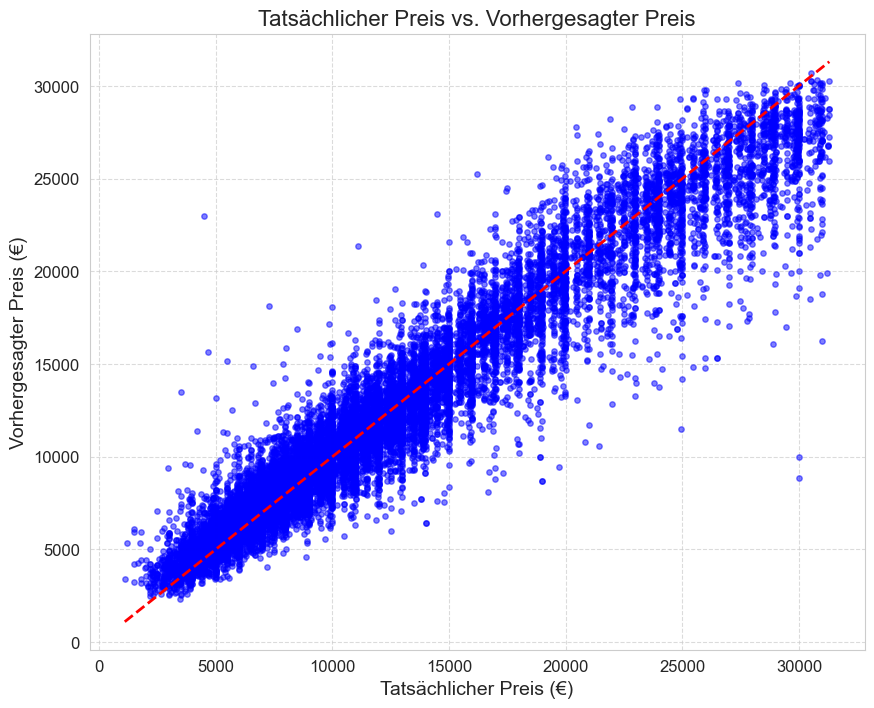

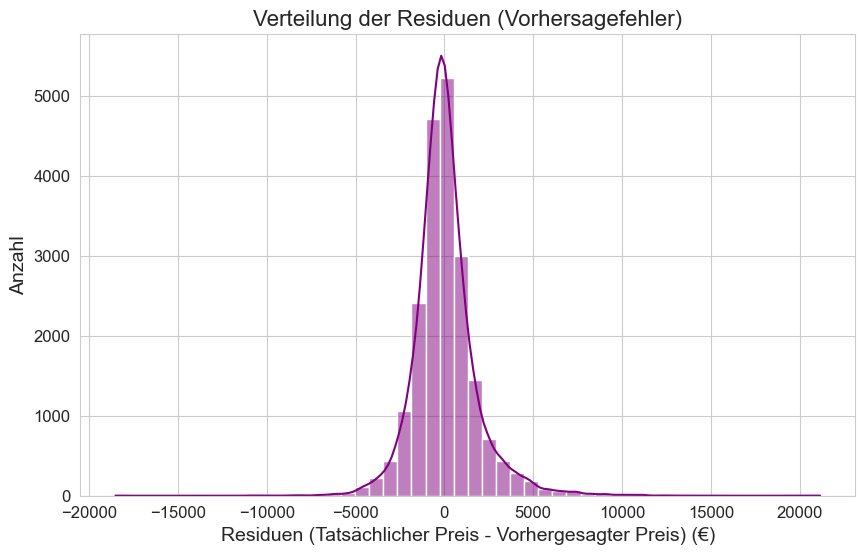

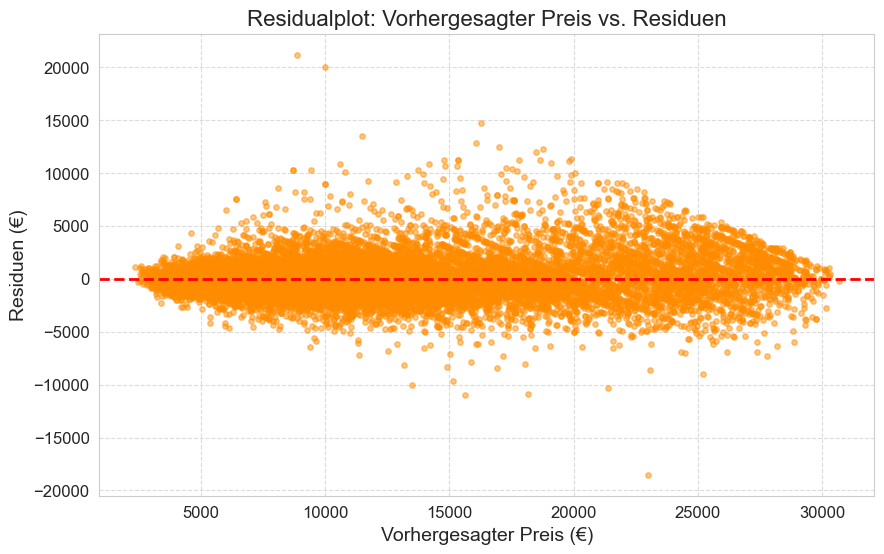


Erkenntnisse aus den Plots (siehe obenstehende Visualisierungen):
- Der Scatter Plot zeigt die Qualität der Vorhersagen, idealerweise liegen Punkte nahe an der Diagonale.
- Die Residuen-Plots helfen zu erkennen, ob das Modell systematische Fehler macht.


In [32]:
print("\n 6.2 Visualisierung der Modellvorhersagen (Plots von model_trainer.py)")

# Zeige die Plots, die von der Funktion zurückgegeben wurden
if 'scatter_plot' in model_plots:
    display(model_plots['scatter_plot'])

if 'residuals_hist' in model_plots:
    display(model_plots['residuals_hist'])

if 'residuals_plot' in model_plots:
    display(model_plots['residuals_plot'])

print("\nErkenntnisse aus den Plots (siehe obenstehende Visualisierungen):")
print("- Der Scatter Plot zeigt die Qualität der Vorhersagen, idealerweise liegen Punkte nahe an der Diagonale.")
print("- Die Residuen-Plots helfen zu erkennen, ob das Modell systematische Fehler macht.")

## 6.3 Analyse der Feature Importance


 6.3 Analyse der Feature Importance (Ergebnisse von model_trainer.py) 

Top 15 Feature Importances:


,Feature,Importance
1,num__hp,0.185661
3,num__year,0.135257
0,num__mileage,0.133302
2,num__age,0.127199
633,cat__gear_Automatic,0.080053
634,cat__gear_Manual,0.054557
640,cat__offerType_Used,0.023231
7,cat__make_Audi,0.010314
639,cat__offerType_Pre-registered,0.010223
637,cat__offerType_Employee's car,0.009077


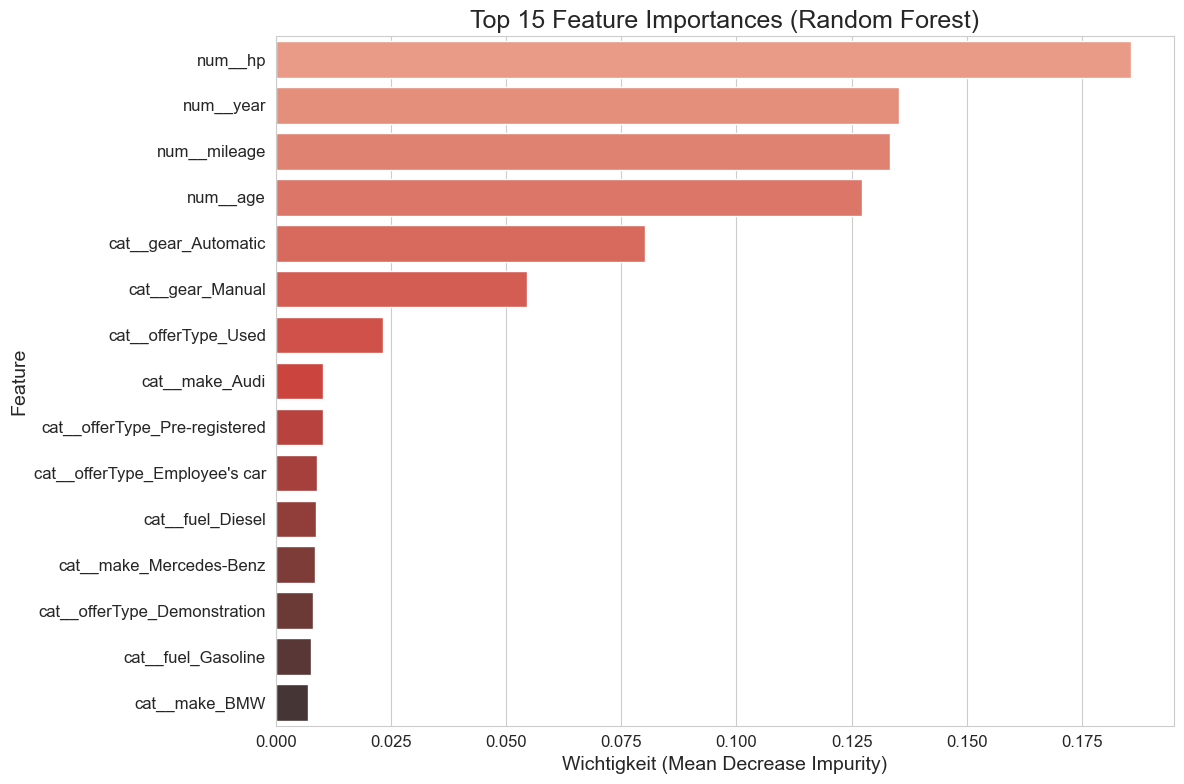


Erkenntnisse zur Feature Importance:
- Die Wichtigkeit der einzelnen Merkmale gibt Aufschluss darüber, welche Faktoren den größten Einfluss auf den Preis haben.
- Typischerweise sind Features wie 'hp' (PS), 'mileage' (Kilometerstand) und 'age' (Alter) sehr einflussreich.

--- Modellierung und Bewertung abgeschlossen ---


In [33]:
print("\n 6.3 Analyse der Feature Importance (Ergebnisse von model_trainer.py) ")
print("\nTop 15 Feature Importances:")
display(feature_importances_df.head(15)) # Zeige den DataFrame direkt an

if 'feature_importance_plot' in model_plots:
    display(model_plots['feature_importance_plot'])

print("\nErkenntnisse zur Feature Importance:")
print("- Die Wichtigkeit der einzelnen Merkmale gibt Aufschluss darüber, welche Faktoren den größten Einfluss auf den Preis haben.")
print("- Typischerweise sind Features wie 'hp' (PS), 'mileage' (Kilometerstand) und 'age' (Alter) sehr einflussreich.")

print("\n--- Modellierung und Bewertung abgeschlossen ---")